# Golden model and replay of the vision chain (R7)

**MTRX3700 Group 26** · owner: Wilson (M2, image processing) · `golden/image_processing_golden.ipynb`

What this notebook demonstrates, top to bottom:

1. **The golden model**: a bit-exact Python model (`golden/model.py`) of the whole vision chain exactly as `major_project_top` builds it:

   `ov7670_capture` stream → **`camera_stream_adapter`** (frame lock, raster check, one close per frame) → **`red_mask`** (`led_colour_mask`, red) → **`led_centroid`** (accumulate, gates, divide; **SW1** = `gate_bypass`)

   plus Wilson's tri-colour path (`led_colour_mask` R/G/B → `colour_run_filter` → 3 × `led_centroid`, i.e. `tri_led_detect`), which is not yet in the top.
   The model is written from each module's specified behaviour (frame-level state machine, closed-form centroid, explicit timing rules), not by copying RTL registers.
2. **Model vs RTL** on generated camera streams: every centroid gate, all 65,536 colour codes, lab-photo frames at real camera timing, every adapter fault, random fuzz, both SW1 modes. Every output record of every cycle must be equal.
3. **Replay of a board capture: board vs model vs RTL.** `vision_tap` + SignalTap record the real chain on the DE1-SoC; the recorded camera stream is replayed through the model and the RTL, and both must reproduce what the board computed, pixel by pixel and frame by frame. The model also explains *why* the board accepted or rejected each frame (confidence, gate flags, bounding box), which the board itself does not export.

Until real captures exist, section 3 uses a **simulated board**: the real `major_project_top` driven from its camera pins by Ed's OV7670 model (`golden/capture_sim.py`). The capture format, parser and checks are identical to the real path.

In [1]:
# ---- settings ---------------------------------------------------------------
QUICK   = True          # False: every fuzz seed and photo scene (several minutes)
CAPTURE = "data/captures/sim_photo"   # a capture directory or a SignalTap export (.vcd/.csv/.taplog)
RUN_RTL = "auto"        # True / False / "auto" (= if Verilator is on PATH)

import os, sys, time, inspect
from pathlib import Path
HERE = Path.cwd() if (Path.cwd() / "model.py").exists() else Path.cwd() / "golden"
sys.path.insert(0, str(HERE))
os.chdir(HERE)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import model, vlog, stimulus, compare, capture, replay, plots
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
if RUN_RTL == "auto":
    RUN_RTL = replay.have_rtl()
print("repository:", HERE.parent)
print("RTL replay with Verilator:", "yes" if RUN_RTL else "NO - model-only (run golden/check_golden.py on Ed for the RTL comparison)")

repository: /home/claude/work
RTL replay with Verilator: yes


## 1. The model

The pixel stage is a pure function of the RGB565 word. A colour is accepted when its channel reaches `MIN`, the two other channels stay below their ceilings, and it beats both by `MARGIN` (so at most one colour per pixel; white, black and the secondaries are rejected):

In [2]:
print(inspect.getsource(model.colour_classes))

def colour_classes(rgb, p: MaskParams = MaskParams()):
    """led_colour_mask: (is_red, is_green, is_blue) boolean arrays.

    A colour is accepted when its channel reaches MIN, the other two stay at or
    below their ceilings, and it beats both of them by at least MARGIN. With
    every MARGIN >= 1 at most one colour can be true per pixel."""
    r, g6, g, b = split565(rgb)
    red = ((r >= p.RED_MIN) & (g6 <= p.RED_GREEN6_MAX) & (b <= p.RED_BLUE_MAX)
           & (r >= g + p.RED_MARGIN) & (r >= b + p.RED_MARGIN))
    green = ((g >= p.GREEN_MIN) & (r <= p.GREEN_RED_MAX) & (b <= p.GREEN_BLUE_MAX)
             & (g >= r + p.GREEN_MARGIN) & (g >= b + p.GREEN_MARGIN))
    blue = ((b >= p.BLUE_MIN) & (r <= p.BLUE_RED_MAX) & (g6 <= p.BLUE_GREEN6_MAX)
            & (b >= r + p.BLUE_MARGIN) & (b >= g + p.BLUE_MARGIN))
    return red, green, blue



The frame stage is the closed-form centroid with `led_centroid`'s gates. The RTL computes the same quantities with accumulators and a 32-step restoring divider; the model uses exact integer floor division:

In [3]:
print(inspect.getsource(model.centroid_result))

def centroid_result(xs, ys, bypass: bool, p: CentroidParams = CentroidParams()):
    """led_centroid's result for one frame's target pixels (x, y arrays).

    count, bounding box, box area; gates
        flags[0] too few   count < MIN_PIXELS (or 0)
        flags[1] too many  count > MAX_PIXELS
        flags[2] aspect    box_w > MAX_ASPECT*box_h or box_h > MAX_ASPECT*box_w
        low_fill           confidence < MIN_CONFIDENCE,
                           confidence = min(255, floor(256*count / area))
    accept = !flags[0] in bypass (V1), else no flag and no low_fill.
    target = floor(sum/count), reported only when accepted."""
    xs = np.asarray(xs, dtype=np.int64)
    ys = np.asarray(ys, dtype=np.int64)
    n = int(len(xs))
    if n:
        x0, x1, y0, y1 = int(xs.min()), int(xs.max()), int(ys.min()), int(ys.max())
        bw, bh = x1 - x0 + 1, y1 - y0 + 1
        sx, sy = int(xs.sum()) & 0xFFFFFFFF, int(ys.sum()) & 0xFFFFFFFF
    else:
        x0 = x1 = y0 = y1 = 0
        bw = 

Timing rules the model also predicts (and the replay checks): adapter outputs are registered on the same edge that samples the input; `frame_done` comes **35 PCLKs** after the frame close; a close arriving within **34 PCLKs** of an accepted close produces no result. The parameters are the RTL defaults; `check_golden.py` parses the RTL and fails if they drift.

In [4]:
import check_golden
check_golden.check_params(); check_golden.check_v1()
pd.DataFrame([(k, v, "led_colour_mask / red_mask") for k, v in model.MaskParams().__dict__.items()] +
             [(k, v, "led_centroid") for k, v in model.CentroidParams().__dict__.items()],
             columns=["parameter", "value", "module"])

PASS: golden params (model parameters == RTL defaults, top uses defaults)


PASS: golden v1_equiv (3900 red codes, 0 differ from V1)


,parameter,value,module
0,RED_MIN,20,led_colour_mask / red_mask
1,RED_GREEN6_MAX,24,led_colour_mask / red_mask
2,RED_BLUE_MAX,12,led_colour_mask / red_mask
3,RED_MARGIN,8,led_colour_mask / red_mask
4,GREEN_MIN,18,led_colour_mask / red_mask
5,GREEN_RED_MAX,14,led_colour_mask / red_mask
6,GREEN_BLUE_MAX,20,led_colour_mask / red_mask
7,GREEN_MARGIN,6,led_colour_mask / red_mask
8,BLUE_MIN,18,led_colour_mask / red_mask
9,BLUE_RED_MAX,14,led_colour_mask / red_mask


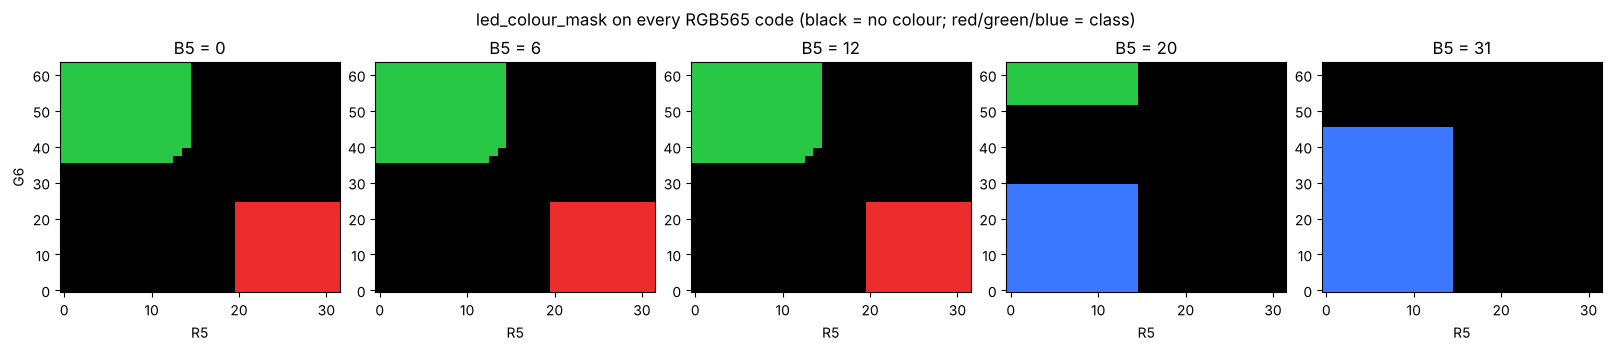

In [5]:
fig = plots.show_classification_map()

## 2. Golden model vs RTL on generated streams

Each stream is written as a `.stim` file and run through the **real RTL** (`golden/sim/vision_replay_tb.sv`: adapter → red_mask → led_centroid, plus tri_led_detect, under Verilator) and through the model. Both write the same record format (`golden/vlog.py`): every accepted pixel with its mask bits, every `frame_start`/`frame_end`, the adapter's diagnostics, and every centroid result with confidence, gate flags and bounding box. The comparison is exact, record by record and field by field.

In [6]:
t = time.time()
results = replay.run_scenarios(quick=QUICK, rtl=RUN_RTL, log=None)
print(f"{len(results)} streams in {time.time()-t:.0f} s")
rows = []
for r in results:
    c = r.model_rec.count()
    rows.append(dict(stream=r.name, frame=f"{r.params.adapter.W}x{r.params.adapter.H}", pixels=c["P"],
                     frames_closed=c["E"], results=c["R"], tri_results=c["T"],
                     **({"model == RTL": "MATCH" if r.report.ok else "MISMATCH"} if RUN_RTL else {})))
scen = pd.DataFrame(rows)
scen

20 streams in 44 s


,stream,frame,pixels,frames_closed,results,tri_results,model == RTL
0,synthetic_gates,640x480,4608000,15,15,45,MATCH
1,photo_camera_timing,640x480,1228800,4,4,12,MATCH
2,adapter_lock_mid_frame,32x24,1536,2,2,6,MATCH
3,adapter_truncated,32x24,1152,2,2,6,MATCH
4,adapter_skip_pixel,32x24,935,2,2,6,MATCH
5,adapter_repeat_pixel,32x24,936,2,2,6,MATCH
6,adapter_x_out_of_range,32x24,935,2,2,6,MATCH
7,adapter_missing_row,32x24,960,2,2,6,MATCH
8,adapter_extra_pixels_and_fs_valid,32x24,1536,2,2,6,MATCH
9,adapter_close_while_busy,32x24,1536,5,3,9,MATCH


In [7]:
if RUN_RTL:
    bad = [r for r in results if not r.report.ok]
    tot = {k: sum(r.report.types[k].n_a for r in results) for k in "PSEDZRT"}
    print("records compared:", tot)
    print("ALL STREAMS MATCH" if not bad else f"{len(bad)} STREAMS DIFFER")
    for r in bad[:3]:
        print(r.report.summary())
    display(results[0].report.table())

records compared: {'P': 5908612, 'S': 175, 'E': 135, 'D': 267, 'Z': 20, 'R': 133, 'T': 399}
ALL STREAMS MATCH


,type,what,model,RTL,mismatches,result
0,P,adapter pixels + masks,4608000,4608000,0,ok
1,S,adapter frame_start,15,15,0,ok
2,E,adapter frame_end/frame_good,15,15,0,ok
3,D,adapter diagnostics,30,30,0,ok
4,Z,adapter final diagnostics,1,1,0,ok
5,R,led_centroid results (robot path),15,15,0,ok
6,T,tri_led_detect results,45,45,0,ok


### 2.1 Every centroid gate, both SW1 modes

The synthetic frames hit each gate of `led_centroid` (too few / too many pixels, aspect ratio, fill confidence) plus the image borders, a saturated white core, speckle noise, all 65,536 colour codes and pixels clustered within ±2 of every threshold. With **SW1 = 1** (R9 bypass) only the minimum-pixel gate remains, so the same frames that V2 rejects are accepted:

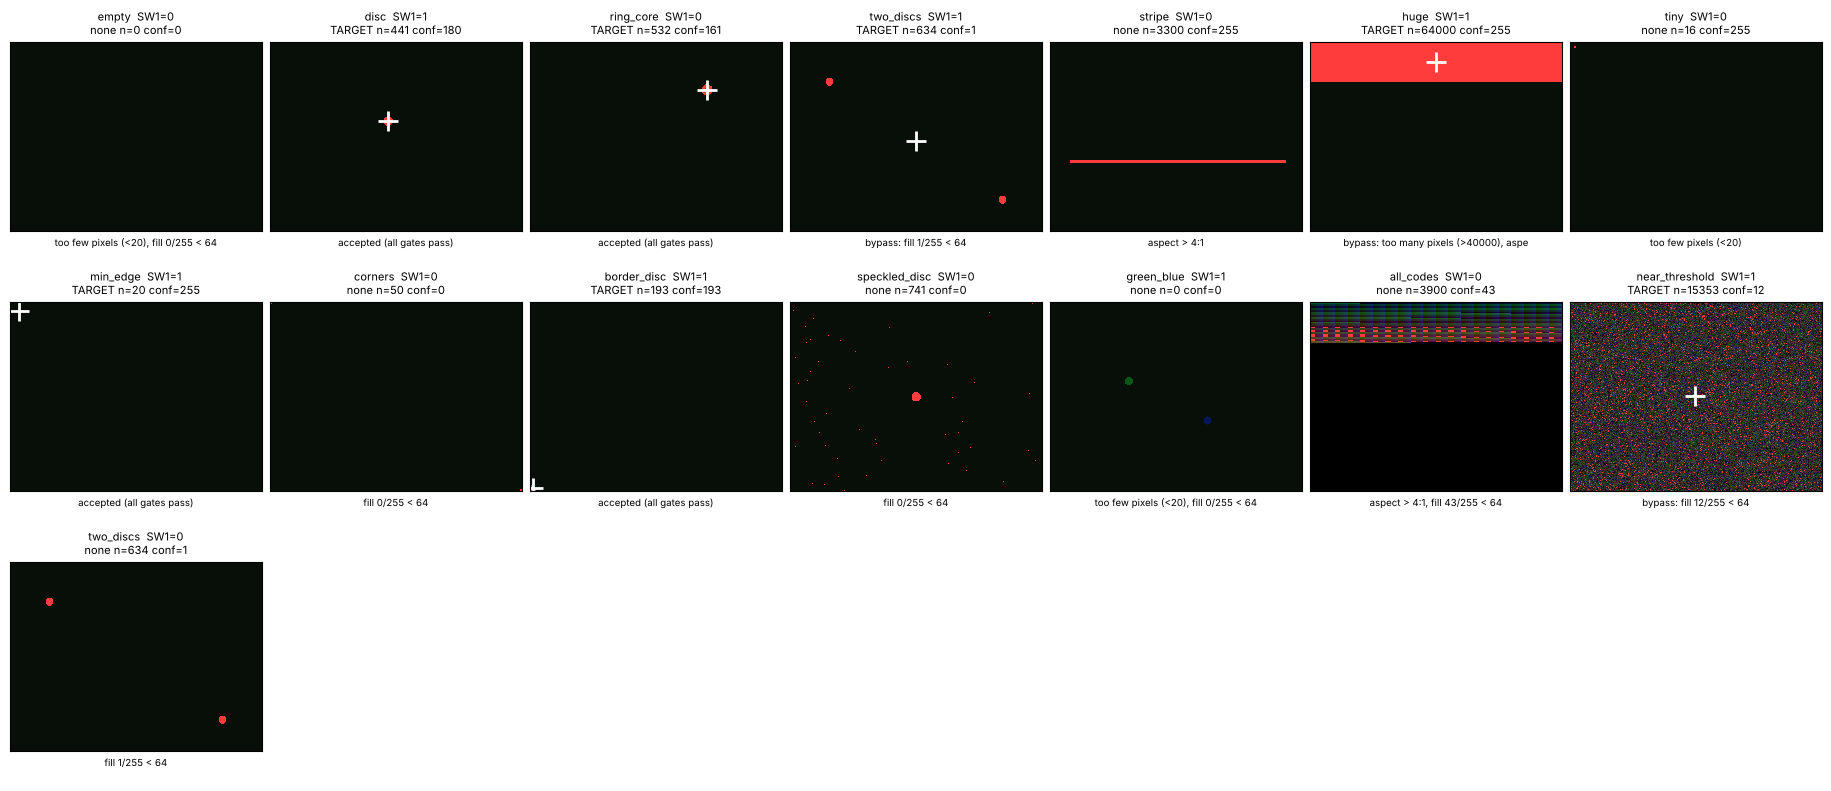

In [8]:
g = next(r for r in results if r.name == "synthetic_gates")
F = stimulus.synthetic_frames()
names = list(F)
seq = names + ["two_discs"] if QUICK else names * 2
sws = [int(g.events["sw1"][np.searchsorted(g.events["cycle"], r["cycle"], side="right") - 1]) for r in g.model.results]
fig = plots.show_gate_gallery(g.model.results, [F[n] for n in seq], seq, sws)

In [9]:
pd.DataFrame([dict(frame=n, SW1=s, target=bool(r["valid"]), x=r["x"], y=r["y"], count=r["count"], confidence=r["conf"],
                   flags=f"{r['flags']:04b}", decision=replay.reject_reason(r))
              for n, s, r in zip(seq, sws, g.model.results)])

,frame,SW1,target,x,y,count,confidence,flags,decision
0,empty,0,False,0,0,0,0,1001,"rejected: too few pixels (<20), fill 0/255 < 64"
1,disc,1,True,300,200,441,180,0000,accepted (all gates pass)
2,ring_core,0,True,450,120,532,161,0000,accepted (all gates pass)
3,two_discs,1,True,320,250,634,1,1000,accepted by SW1 bypass despite: fill 1/255 < 64
4,stripe,0,False,0,0,3300,255,0100,rejected: aspect > 4:1
5,huge,1,True,319,49,64000,255,0110,"accepted by SW1 bypass despite: too many pixels (>40000), aspect > 4:1"
6,tiny,0,False,0,0,16,255,0001,rejected: too few pixels (<20)
7,min_edge,1,True,22,21,20,255,0000,accepted (all gates pass)
8,corners,0,False,0,0,50,0,1000,rejected: fill 0/255 < 64
9,border_disc,1,True,6,472,193,193,0000,accepted (all gates pass)


### 2.2 Adapter fault handling

Small 32×24 frames (the bench is built with `-GW=32 -GH=24`) with hand-written stream faults: capture starting mid-frame, truncated frames, skipped/repeated pixels, x out of range, a missing row, extra pixels after a frame, a pixel on the `frame_start` cycle, closes inside the centroid's 34-cycle busy window, and SW1 toggling. Each rejected frame must give an explicit *no target*; the busy-window case shows closes that produce **no** result at all.

In [10]:
edge = [r for r in results if r.name.startswith("adapter_")]
pd.DataFrame([dict(case=r.name[8:], closes=len(r.model_rec["E"]),
                   good=int(r.model_rec["E"][:, 1].sum()) if len(r.model_rec["E"]) else 0,
                   results=len(r.model_rec["R"]), targets=int(r.model_rec["R"][:, 1].sum()) if len(r.model_rec["R"]) else 0,
                   dropped=int(r.model_rec["Z"][0, 5]),
                   closes_seen=", ".join(k for _, k in r.model.adapter.closes) or "-",
                   **({"model == RTL": "MATCH" if r.report.ok else "MISMATCH"} if RUN_RTL else {}))
              for r in edge])

,case,closes,good,results,targets,dropped,closes_seen,model == RTL
0,lock_mid_frame,2,2,2,2,50,"good, good",MATCH
1,truncated,2,1,2,1,0,"truncated, good",MATCH
2,skip_pixel,2,1,2,1,600,"coordinate, good",MATCH
3,repeat_pixel,2,1,2,1,601,"coordinate, good",MATCH
4,x_out_of_range,2,1,2,1,601,"coordinate, good",MATCH
5,missing_row,2,1,2,1,544,"coordinate, good",MATCH
6,extra_pixels_and_fs_valid,2,2,2,2,6,"good, good",MATCH
7,close_while_busy,5,2,3,2,0,"good, truncated, truncated, truncated, good",MATCH
8,bypass_toggle,2,2,2,1,0,"good, good",MATCH
9,never_synced,0,0,0,0,200,-,MATCH


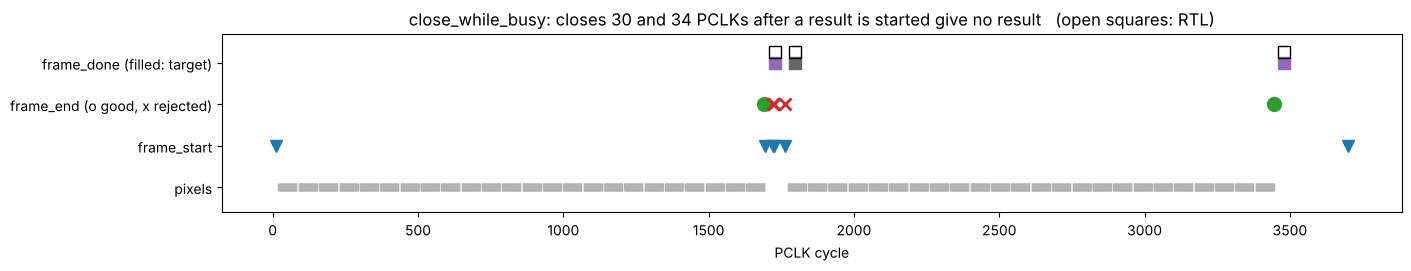

In [11]:
r = next(r for r in results if r.name == "adapter_close_while_busy")
fig = plots.show_timeline(r.model_rec, "close_while_busy: closes 30 and 34 PCLKs after a result is started give no result",
                          r.rtl_rec if RUN_RTL else None)

## 3. Board capture: board vs golden model vs RTL

`golden/rtl/vision_tap.sv` (wired into the top with `golden/rtl/vision_tap_hookup.svh`) records, through SignalTap with `tap_store` as storage qualifier:

* every `frame_start` (frame period, SW1, band position);
* for every frame, **all** pixels of 8 dense rows around the last target, plus every pixel anywhere that is *loosely* red (a strict superset of `red_mask`) or that the board's `red_mask` marked red, each with the board's verdict (adapter accepted it, `is_red`, any close);
* every `led_centroid` result with the latency from the frame close.

Pixels that are not recorded are, provably, not red for the board **and** not red for the model, so each recorded frame is rebuilt with them black and replayed: the rebuilt frame has exactly the real frame's centroid result. The checks below compare the board's recorded verdict on every recorded pixel and every frame result with the model and with the RTL replay, and check the board's timing.

In [12]:
t = time.time()
cr = replay.replay_capture(CAPTURE, rtl=RUN_RTL)
print(f"capture {CAPTURE}: {len(cr.cap.words)} SignalTap samples, {len(cr.cap.frames)} frames, replayed in {time.time()-t:.0f} s")
print("ALL CAPTURE CHECKS PASS" if cr.ok else "SOME CAPTURE CHECKS FAIL")
cr.table()

capture data/captures/sim_photo: 32768 SignalTap samples, 6 frames, replayed in 11 s
ALL CAPTURE CHECKS PASS


,check,result,detail
0,"capture integrity (seq toggles, every result assigned)",PASS,"32768 samples, 0 seq errors, 0 unassigned results"
1,vision_tap loose filter covers every model-red code,PASS,unrecorded pixels cannot be red
2,complete frames in the capture,PASS,5 complete of 6
3,frames the board adapter rejected gave no target,PASS,0 rejected frames
4,"RTL replay == golden model (every record, every field)",PASS,P:1536000; S:5; E:5; D:10; Z:1; R:5; T:15
5,board red_mask == golden model on every recorded pixel,PASS,"28169 pixels (25600 in dense rows), 0 differ"
6,board red_mask == RTL replay on every recorded pixel,PASS,0 differ
7,"board frame result == golden model (valid, x, y, red_count)",PASS,5 frames
8,board frame result == RTL replay,PASS,5 frames
9,board centroid latency == 35 PCLKs after the frame close,PASS,measured [35]


In [13]:
cr.cap.board_table()

,frame,close,complete,period_pclk,recorded_px,dense_px,board_red_px,sw1,valid,x,y,count,latency
0,0,good,True,NaN,5365,5120,321,0.0,1.0,430.0,205.0,321.0,35.0
1,1,good,True,799680.0,5365,5120,321,0.0,1.0,430.0,205.0,321.0,35.0
2,2,good,True,799680.0,5813,5120,676,0.0,0.0,0.0,0.0,676.0,35.0
3,3,good,True,799680.0,5813,5120,676,0.0,0.0,0.0,0.0,676.0,35.0
4,4,good,True,799680.0,5813,5120,676,1.0,1.0,267.0,271.0,676.0,35.0
5,5,open,False,799680.0,4588,4202,321,NaN,NaN,NaN,NaN,NaN,NaN


Per frame, what the board decided, what the model and the RTL decide on the same recorded pixels, and the model's explanation (the board exports only valid/x/y/count; confidence, flags and bounding box come from the model):

In [14]:
cr.frame_table()

,frame,SW1,board,model,RTL,confidence,flags,reason,bbox,latency
0,0,0,"valid (430,205) n=321","valid (430,205) n=321","valid (430,205) n=321",186,0000,accepted (all gates pass),"x 420-440, y 196-216",35
1,1,0,"valid (430,205) n=321","valid (430,205) n=321","valid (430,205) n=321",186,0000,accepted (all gates pass),"x 420-440, y 196-216",35
2,2,0,"none (0,0) n=676","none (0,0) n=676","none (0,0) n=676",3,1000,rejected: fill 3/255 < 64,"x 109-440, y 196-342",35
3,3,0,"none (0,0) n=676","none (0,0) n=676","none (0,0) n=676",3,1000,rejected: fill 3/255 < 64,"x 109-440, y 196-342",35
4,4,1,"valid (267,271) n=676","valid (267,271) n=676","valid (267,271) n=676",3,1000,accepted by SW1 bypass despite: fill 3/255 < 64,"x 109-440, y 196-342",35


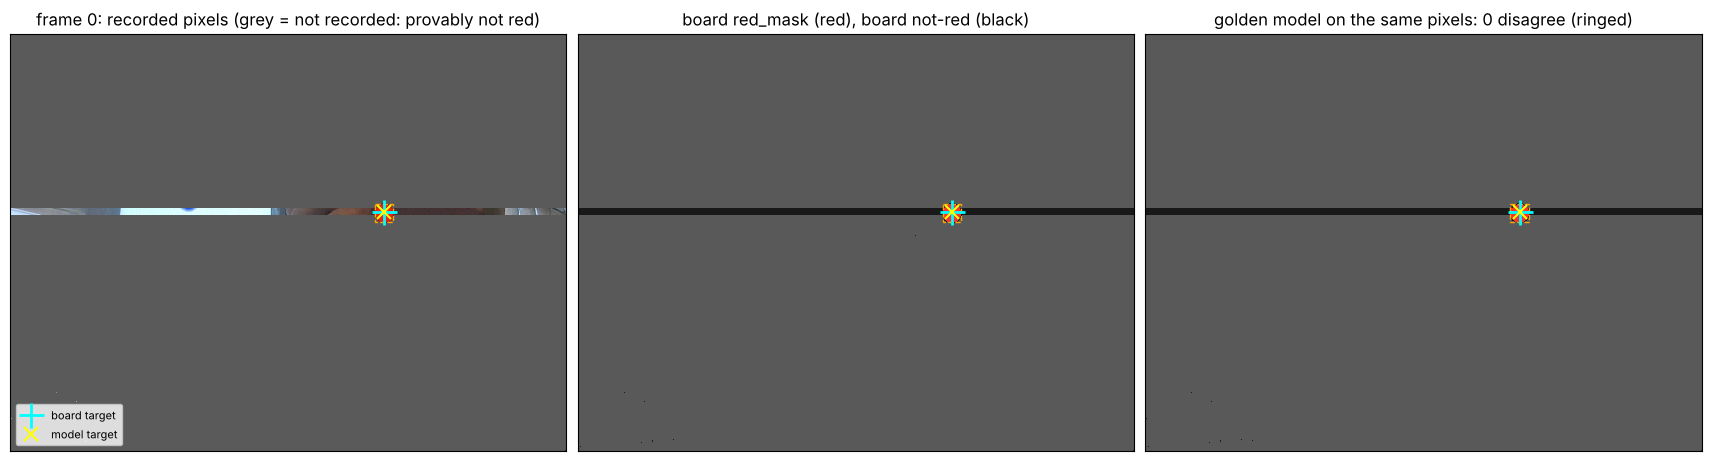

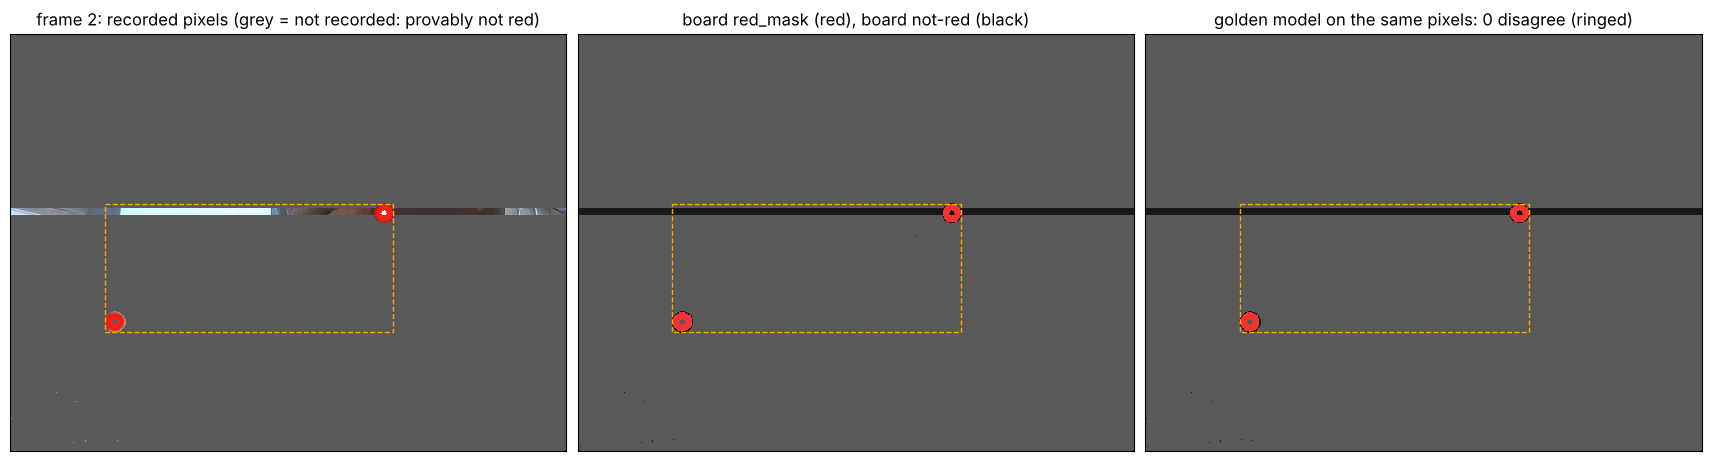

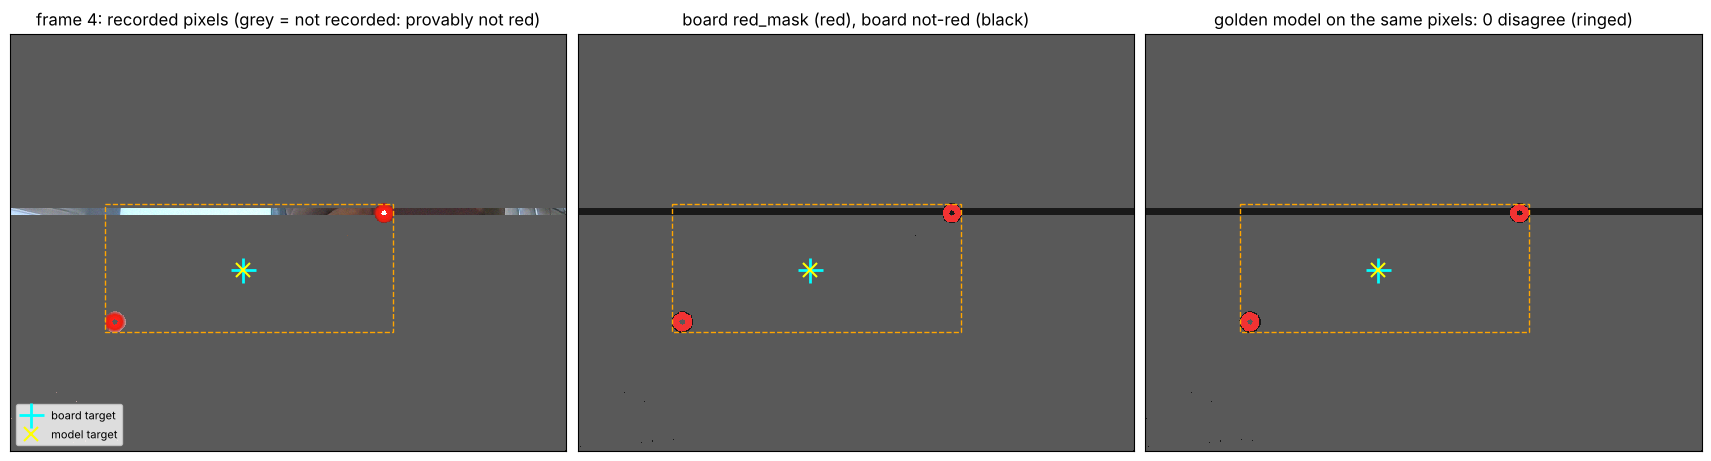

In [15]:
for k in range(len(cr.frames)):
    f = cr.frames[k]
    if k in (0, len(cr.frames) - 1) or (k > 0 and cr.frames[k - 1].result["sw1"] != f.result["sw1"]) or \
       (k > 0 and cr.frames[k - 1].result["count"] != f.result["count"]):
        fig = plots.show_capture_frame(cr, k)

Zoom on the target of the first frame: the dense rows (all classes recorded) and the sparse loose-red pixels around the LED.

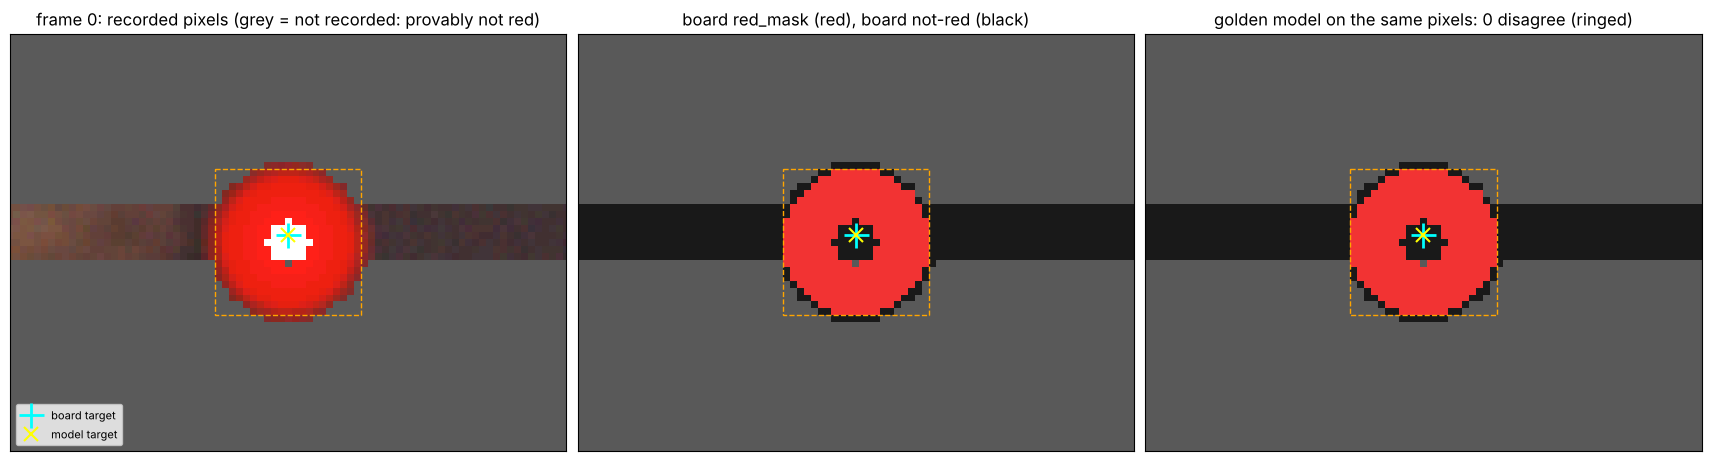

In [16]:
f0 = cr.model.results[0]
if f0["count"]:
    cx, cy = (f0["bx0"] + f0["bx1"]) // 2, (f0["by0"] + f0["by1"]) // 2
    fig = plots.show_capture_frame(cr, 0, zoom=(cx - 40, cy - 30, 80, 60))

### 3.1 Timing seen on the board

The capture also records cycle stamps, so the board's timing is checked against the model: the centroid latency (35 PCLKs after the close), the frame period (OV7670: 510 lines × 1568 PCLKs = 799,680 PCLKs = 50.0 fps at 40 MHz) and the pixel cadence (one pixel every 2 PCLKs).

frame rate 50.020 fps at PCLK = 40 MHz


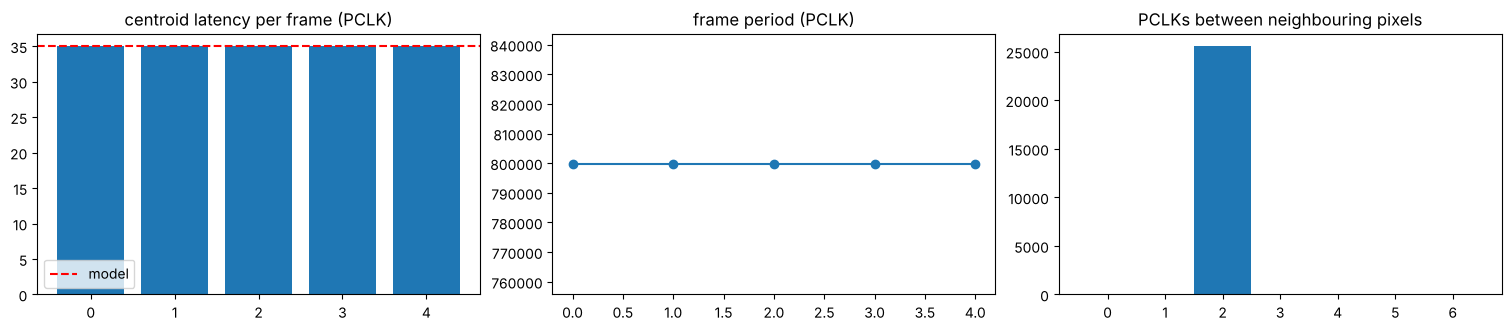

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.2), constrained_layout=True)
lat = [f.result["latency"] for f in cr.cap.frames if f.result]
axs[0].bar(range(len(lat)), lat); axs[0].axhline(model.CENTROID_LATENCY, color="r", ls="--", label="model")
axs[0].set_title("centroid latency per frame (PCLK)"); axs[0].legend()
per = [f.period for f in cr.cap.frames[1:]]
axs[1].plot(per, "o-"); axs[1].set_title("frame period (PCLK)"); axs[1].ticklabel_format(useOffset=False)
cad = []
for f in cr.frames:
    p = f.pixels; d = p["band"].astype(bool) & p["accepted"].astype(bool)
    same = (np.diff(p["y"][d]) == 0) & (np.diff(p["x"][d]) == 1)
    cad += list((np.diff(p["cyc"][d]) % 2048)[same])
axs[2].hist(cad, bins=np.arange(0, 8) - 0.5); axs[2].set_title("PCLKs between neighbouring pixels")
print(f"frame rate {40e6/np.mean(per):.3f} fps at PCLK = 40 MHz" if per else "")

## 4. Recording a real capture on the DE1-SoC

1. Add `golden/rtl/vision_tap.sv` to the Quartus project and paste `golden/rtl/vision_tap_hookup.svh` into `major_project_top.sv` after `u_led_centroid` (the tap only *watches* existing nets).
2. SignalTap (`Tools > Signal Tap Logic Analyzer`): clock `cam_pclk`; nodes `u_vision_tap|tap_word[55..0]` and `u_vision_tap|tap_store`; **storage qualifier: Input port = `tap_store`**; trigger on `u_vision_tap|tap_trigger` = 1; sample depth 32K (16K if M10K runs short); compile, program, run with the LED in view (any SW1 setting, both is best).
3. `File > Export`, as **VCD** (or CSV, bus radix hex).
4. `python golden/capture.py export.vcd -o golden/data/captures/<name>` then set `CAPTURE = "data/captures/<name>"` at the top of this notebook and re-run. `python golden/check_golden.py` replays every capture in `golden/data/captures/` too.

Details and troubleshooting: `golden/README.md`.

## 5. Verdict

In [18]:
rows = []
if RUN_RTL:
    rows.append(("golden model == RTL on generated streams", all(r.report.ok for r in results),
                 f"{len(results)} streams, {sum(r.report.types['P'].n_a for r in results):,} pixels"))
rows += [(c, ok, d) for c, ok, d in cr.checks]
v = pd.DataFrame(rows, columns=["check", "ok", "detail"])
v["result"] = np.where(v["ok"], "PASS", "FAIL")
print("GOLDEN MODEL AND REPLAY:", "PASS" if v["ok"].all() else "FAIL")
v[["check", "result", "detail"]]

GOLDEN MODEL AND REPLAY: PASS


,check,result,detail
0,golden model == RTL on generated streams,PASS,"20 streams, 5,908,612 pixels"
1,"capture integrity (seq toggles, every result assigned)",PASS,"32768 samples, 0 seq errors, 0 unassigned results"
2,vision_tap loose filter covers every model-red code,PASS,unrecorded pixels cannot be red
3,complete frames in the capture,PASS,5 complete of 6
4,frames the board adapter rejected gave no target,PASS,0 rejected frames
5,"RTL replay == golden model (every record, every field)",PASS,P:1536000; S:5; E:5; D:10; Z:1; R:5; T:15
6,board red_mask == golden model on every recorded pixel,PASS,"28169 pixels (25600 in dense rows), 0 differ"
7,board red_mask == RTL replay on every recorded pixel,PASS,0 differ
8,"board frame result == golden model (valid, x, y, red_count)",PASS,5 frames
9,board frame result == RTL replay,PASS,5 frames
